# Lorenz '63 — Your First sesmax Simulation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/lorenz63_simulation.ipynb)

*Part of [Chaos and predictability](../guide/chaos_and_predictability.md); moved from somax's tutorial series.*

The [Lorenz '63 system](https://en.wikipedia.org/wiki/Lorenz_system) is the canonical low-dimensional chaotic attractor. It is the simplest model in sesmax and a good starting point for understanding the API.

**What you'll learn:**

1. How to create a model, a state and a forward simulation
2. How the `Model` contract works (`vector_field`, `integrate`, `diagnose`)
3. How to differentiate through a simulation with `jax.grad`
4. How to run an ensemble with `jax.vmap`

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## Background

The system is defined by three coupled ODEs with parameters $\sigma$ (Prandtl number), $\rho$ (Rayleigh number) and $\beta$ (geometric factor):

$$
\frac{\mathrm{d}x}{\mathrm{d}t} = \sigma (y - x)
$$

$$
\frac{\mathrm{d}y}{\mathrm{d}t} = x (\rho - z) - y
$$

$$
\frac{\mathrm{d}z}{\mathrm{d}t} = x y - \beta z
$$

At the standard parameters $(\sigma, \rho, \beta) = (10, 28, 8/3)$ the system exhibits deterministic chaos: nearby trajectories diverge exponentially, tracing the famous butterfly-shaped strange attractor.

### Symbols

Here $x$, $y$ and $z$ are the three state variables, not coordinates, and they stack into the state vector $\mathbf{x}$.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x(t)$, $y(t)$, $z(t)$ | the three state variables | $\mathbb{R}$ |
| $\mathbf{x}(t) = (x, y, z)$, $\mathbf{x}_0$ | state vector and initial state | $\mathbb{R}^{3}$ |
| $\boldsymbol{\theta} = (\sigma, \rho, \beta)$ | parameters | $\mathbb{R}^{3}$ |
| $f(\mathbf{x}; \boldsymbol{\theta})$ | the right-hand side | $\mathbb{R}^{3}$ |
| $t \in [0, t_1]$, $\Delta t$ | time, window end and time step | $\mathbb{R}$ |
| $N_T$ | number of saved snapshots | count |
| $E(t)$ | energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $\boldsymbol{\lambda}(t)$ | adjoint state | $\mathbb{R}^{3}$ |
| $N_{\mathcal{E}}$ | number of ensemble members | count |
| $\delta(t)$, $\delta_0$ | separation of two trajectories, and its reference value | $\mathbb{R}_{\ge 0}$ |
| $\lambda$ | leading Lyapunov exponent | $\mathbb{R}$ |
| $\tau$, $N_W$, $\delta_w$ | rescaling window, number of windows, and the gap at the end of window $w$ | $\mathbb{R}_{>0}$, count, $\mathbb{R}_{\ge 0}$ |

In [2]:
import time

import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`Lorenz63.create()` builds a model with the standard parameter values. The model is an `eqx.Module`, an immutable pytree whose fields (including `params`) are visible to `jax.grad` and `jax.jit`.

In [4]:
# today (sesmax_core)
model = sxt.Lorenz63.create(sigma=10.0, rho=28.0, beta=8.0 / 3.0)
print(model)

Lorenz63(params=L63Params(sigma=weak_f32[], rho=weak_f32[], beta=weak_f32[]))


## 2. Forward simulation

`model.integrate()` wraps `diffrax.diffeqsolve` and applies the model's boundary conditions, which do nothing for this system. We save the trajectory at dense output times to visualise the attractor.

In [5]:
# Shapes: N_T = 4,000 saved snapshots

start_time = 0.0
end_time = 40.0
time_step = 0.01

# today (sesmax_core)
# x₀ = (1, 1, 1)
initial_state = sxt.L63State(x=jnp.array(1.0), y=jnp.array(1.0), z=jnp.array(1.0))

# tₖ = t₀ + k Δt
save_times = jnp.arange(start_time, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
solution = model.integrate(  # x, y, z → (N_T,) each
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Trajectory shape: x={solution.ys.x.shape}, y={solution.ys.y.shape}")

Trajectory shape: x=(4000,), y=(4000,)


## 3. Visualise the attractor

The classic 3D butterfly and the three time series.

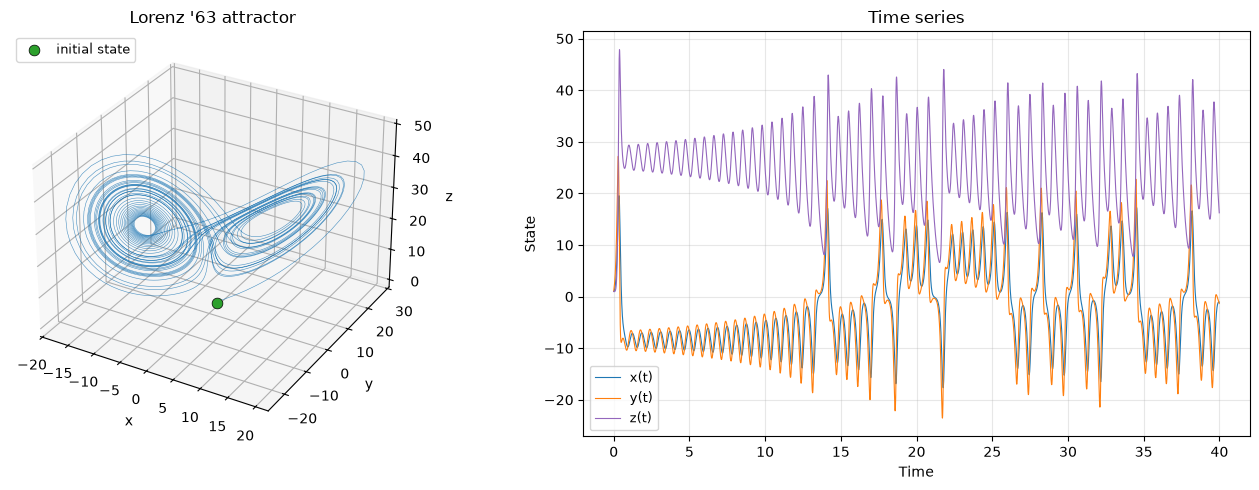

In [6]:
fig = plt.figure(figsize=(14, 5))

ax3d = fig.add_subplot(121, projection="3d")
ax3d.plot(solution.ys.x, solution.ys.y, solution.ys.z, lw=0.4, alpha=0.8, color="C0")
ax3d.scatter(
    [solution.ys.x[0]],
    [solution.ys.y[0]],
    [solution.ys.z[0]],
    s=60,
    c="C2",
    edgecolors="k",
    linewidths=0.5,
    zorder=5,
    label="initial state",
)
ax3d.set_xlabel("x")
ax3d.set_ylabel("y")
ax3d.set_zlabel("z")
ax3d.set_title("Lorenz '63 attractor")
ax3d.legend(loc="upper left", fontsize=9)

ax = fig.add_subplot(122)
ax.plot(save_times, solution.ys.x, lw=0.8, color="C0", label="x(t)")
ax.plot(save_times, solution.ys.y, lw=0.8, color="C1", label="y(t)")
ax.plot(save_times, solution.ys.z, lw=0.8, color="C4", label="z(t)")
ax.set_xlabel("Time")
ax.set_ylabel("State")
ax.set_title("Time series")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Diagnostics

`model.diagnose()` computes on-demand quantities from the state. For this system it returns the energy

$$
E = \frac{1}{2} (x^2 + y^2 + z^2)
$$

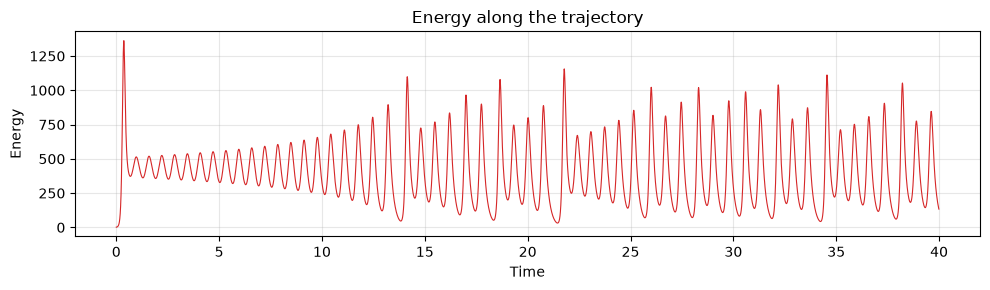

In [7]:
# today (jax, sesmax_core)
energy = jax.vmap(model.diagnose)(solution.ys).energy  # → (N_T,)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(save_times, energy, lw=0.8, color="C3")
ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy along the trajectory")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Adjoint methods for differentiation

Differentiating through an ODE solve requires an **adjoint method** that trades off memory, accuracy and speed. diffrax provides four, for a run of $N$ steps:

| Adjoint | Memory | Gradients | Use case |
| --- | --- | --- | --- |
| `RecursiveCheckpointAdjoint` | $O(\sqrt{N})$ | Exact | **Default** |
| `DirectAdjoint` | $O(N)$ | Exact | Short windows |
| `BacksolveAdjoint` | $O(1)$ | Approximate | Long windows |
| `ImplicitAdjoint` | $O(1)$ | Exact | Steady states |

- **`RecursiveCheckpointAdjoint`**, the default, uses optimal checkpointing: it re-computes forward steps from saved checkpoints during the backward pass, giving exact gradients with sub-linear memory.
- **`DirectAdjoint`** stores the entire forward trajectory, exact but with $O(N)$ memory. It also supports forward-mode differentiation.
- **`BacksolveAdjoint`** solves the continuous adjoint ODE backwards in time with $O(1)$ memory. Its gradients are approximate, because optimising the discretised problem differs from discretising the optimality conditions.
- **`ImplicitAdjoint`** differentiates through the implicit function theorem, which applies only to steady-state and fixed-point problems, not to time-stepping.

### 5a. Gradient with respect to the parameters

**Use case: parameter estimation.** Given observations, find the parameters $\boldsymbol{\theta}$ that minimise a loss. We compute the gradient of $\mathcal{L} = \lVert \mathbf{x}(t_1) \rVert^2$, where the state depends on $\boldsymbol{\theta}$ through the ODE:

$$
\nabla_{\boldsymbol{\theta}} \mathcal{L} = \int_{0}^{t_1} \boldsymbol{\lambda}(t)^\top \frac{\partial f}{\partial \boldsymbol{\theta}} \mathrm{d}t
$$

where the adjoint state $\boldsymbol{\lambda}(t)$ satisfies the backward ODE $\mathrm{d}\boldsymbol{\lambda} / \mathrm{d}t = -(\partial f / \partial \mathbf{x})^\top \boldsymbol{\lambda}$.

In [8]:
def trajectory_loss(state, model):
    """ℒ = ‖x(t₁)‖², over a one-unit window."""
    # today (sesmax_core, diffrax)
    window = model.integrate(state, t0=0.0, t1=1.0, dt=0.01)  # x, y, z → (1,) each
    # ℒ = x(t₁)² + y(t₁)² + z(t₁)²
    return jnp.sum(window.ys.x**2 + window.ys.y**2 + window.ys.z**2)  # → ()


# today (equinox)
# ∇_θ ℒ
parameter_gradient = eqx.filter_grad(lambda m: trajectory_loss(initial_state, m))(model)

print("--- Gradient with respect to the parameters ---")
print(f"  dL/d(sigma) = {float(parameter_gradient.params.sigma):.4f}")
print(f"  dL/d(rho)   = {float(parameter_gradient.params.rho):.4f}")
print(f"  dL/d(beta)  = {float(parameter_gradient.params.beta):.4f}")

--- Gradient with respect to the parameters ---
  dL/d(sigma) = -2.7040
  dL/d(rho)   = 15.1506
  dL/d(beta)  = 331.9409


### 5b. Gradient with respect to the initial state

**Use case: state estimation and data assimilation.** Given a model with known parameters, find the initial condition $\mathbf{x}_0$ that best fits observations, which is the 4D-Var problem. The gradient is the same adjoint state, evaluated at $t = 0$:

$$
\nabla_{\mathbf{x}_0} \mathcal{L} = \boldsymbol{\lambda}(0)
$$

In [9]:
# today (jax)
# ∇_x₀ ℒ
state_gradient = jax.grad(trajectory_loss)(initial_state, model)

print("--- Gradient with respect to the initial state ---")
print(f"  dL/d(x0) = {float(state_gradient.x):.4f}")
print(f"  dL/d(y0) = {float(state_gradient.y):.4f}")
print(f"  dL/d(z0) = {float(state_gradient.z):.4f}")

--- Gradient with respect to the initial state ---
  dL/d(x0) = -21.0364
  dL/d(y0) = -18.2367
  dL/d(z0) = 39.6907


### 5c. Joint gradient: parameters and state

**Use case: joint estimation.** Estimate the initial state and the model parameters together, in a single backward pass. `jax.grad` with `argnums=(0, 1)` returns both.

In [10]:
# today (jax)
# (∇_x₀ ℒ, ∇_θ ℒ)
joint_state, joint_model = jax.grad(trajectory_loss, argnums=(0, 1))(
    initial_state, model
)

print("--- Joint gradient ---")
print(f"  dL/d(x0)    = {float(joint_state.x):.4f}")
print(f"  dL/d(y0)    = {float(joint_state.y):.4f}")
print(f"  dL/d(z0)    = {float(joint_state.z):.4f}")
print(f"  dL/d(sigma) = {float(joint_model.params.sigma):.4f}")
print(f"  dL/d(rho)   = {float(joint_model.params.rho):.4f}")
print(f"  dL/d(beta)  = {float(joint_model.params.beta):.4f}")

--- Joint gradient ---
  dL/d(x0)    = -21.0364
  dL/d(y0)    = -18.2367
  dL/d(z0)    = 39.6907
  dL/d(sigma) = -2.7040
  dL/d(rho)   = 15.1506
  dL/d(beta)  = 331.9409


### 5d. Comparing adjoint methods

We time `RecursiveCheckpointAdjoint` against `DirectAdjoint` on the same problem. `BacksolveAdjoint` requires passing the model as an explicit argument to `diffeqsolve` rather than through a closure, so it needs a different API pattern; the [diffrax docs](https://docs.kidger.site/diffrax/api/adjoints/) have the details. Both exact methods must agree on the gradient, and the time printed is the machine's, so it changes from run to run.

In [11]:
def timed_gradient(adjoint, label):
    """∂ℒ/∂σ with one adjoint, timed after a warm-up run."""

    # today (equinox)
    @eqx.filter_grad
    def gradient(model):
        # today (sesmax_core, diffrax)
        window = model.integrate(
            initial_state, t0=0.0, t1=1.0, dt=0.01, adjoint=adjoint
        )
        # ℒ = x(t₁)² + y(t₁)² + z(t₁)²
        return jnp.sum(window.ys.x**2 + window.ys.y**2 + window.ys.z**2)

    # today (jax)
    jax.block_until_ready(gradient(model).params.sigma)
    start = time.perf_counter()
    result = jax.block_until_ready(gradient(model).params.sigma)
    elapsed = time.perf_counter() - start
    print(f"  {label:25s} dL/d(sigma) = {float(result):.4f} ({elapsed:.4f} s)")


print("--- Adjoint method comparison ---")
# today (diffrax)
timed_gradient(dfx.RecursiveCheckpointAdjoint(), "RecursiveCheckpoint")
timed_gradient(dfx.DirectAdjoint(), "Direct")

--- Adjoint method comparison ---


  RecursiveCheckpoint       dL/d(sigma) = -2.7040 (4.0770 s)


  Direct                    dL/d(sigma) = -2.7040 (5.8630 s)


## 6. Ensemble simulation with `jax.vmap`

Chaotic systems are sensitive to initial conditions. We can explore this by running an ensemble of trajectories with small perturbations and watching them diverge.

In [12]:
# Shapes: N_E = 50 members; N_T = 3,000 saved snapshots

num_members = 50
ensemble_key = jax.random.key(42)

# ε⁽ᵉ⁾ ~ 𝒩(0, 0.01² I₃)
perturbation = 0.01 * jax.random.normal(ensemble_key, (num_members, 3))  # → (N_E, 3)
# today (sesmax_core)
# x₀⁽ᵉ⁾ = (1, 1, 1) + ε⁽ᵉ⁾
ensemble_states = sxt.L63State(
    x=1.0 + perturbation[:, 0],
    y=1.0 + perturbation[:, 1],
    z=1.0 + perturbation[:, 2],
)
ensemble_times = jnp.arange(0.0, 30.0, 0.01)  # → (N_T,)


def integrate_member(member_state):
    # today (sesmax_core, diffrax)
    return model.integrate(
        member_state,
        t0=0.0,
        t1=30.0,
        dt=0.01,
        saveat=dfx.SaveAt(ts=ensemble_times),
    )


# today (equinox)
ensemble = eqx.filter_vmap(integrate_member)(ensemble_states)  # x, y, z → (N_E, N_T)

# sd⁽ᵉ⁾[x(t)]
spread = einx.std("[member] time -> time", ensemble.ys.x)  # → (N_T,)
print(f"Spread of x at t = 1:  {float(spread[100]):.4f}")
print(f"Spread of x at t = 30: {float(spread[-1]):.4f}")

Spread of x at t = 1:  0.0063
Spread of x at t = 30: 8.5092


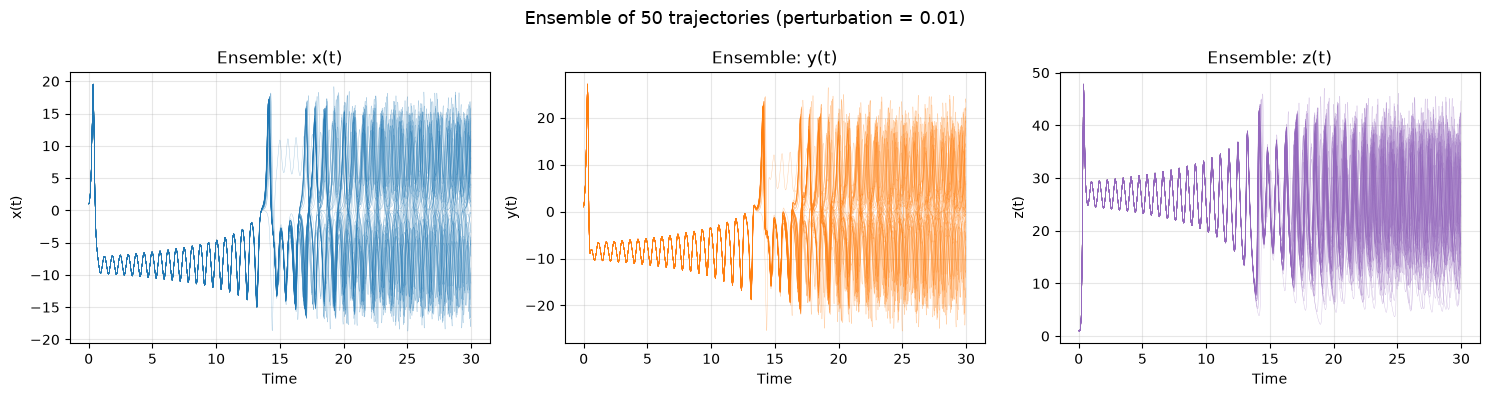

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fields = [ensemble.ys.x, ensemble.ys.y, ensemble.ys.z]
for ax, field, name, color in zip(
    axes, fields, ["x(t)", "y(t)", "z(t)"], ["C0", "C1", "C4"], strict=True
):
    for member in range(num_members):
        ax.plot(ensemble_times, field[member], lw=0.3, alpha=0.4, color=color)
    ax.set_xlabel("Time")
    ax.set_ylabel(name)
    ax.set_title(f"Ensemble: {name}")
    ax.grid(True, alpha=0.3)
plt.suptitle(
    f"Ensemble of {num_members} trajectories (perturbation = 0.01)", fontsize=13
)
plt.tight_layout()
plt.show()

## 7. Sensitive dependence and the Lyapunov exponent

Chaos is quantified by the exponential separation of nearby trajectories: two states a tiny distance $\delta_0$ apart diverge, on average, as $\delta(t) \sim \delta_0 e^{\lambda t}$, where $\lambda > 0$ is the leading Lyapunov exponent, about $0.9$ for this system. We integrate two trajectories whose initial conditions differ by $10^{-6}$ and watch the gap. We use $10^{-6}$ rather than a smaller value because sesmax runs in single precision by default, where perturbations below about $10^{-7}$ vanish into round-off.


Separation at t = 20: 1.51e-01
Separation at t = 40: 20.48


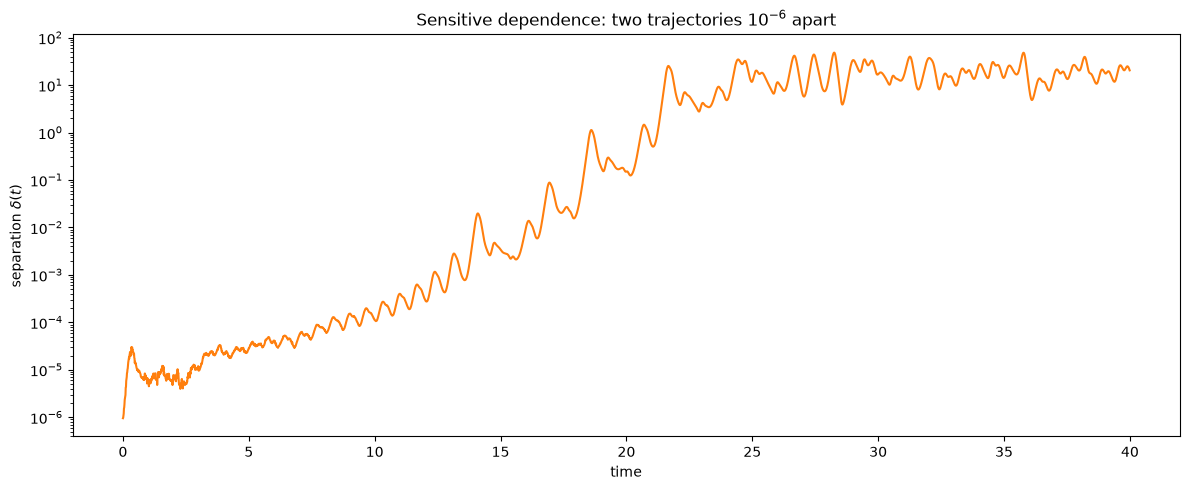

In [14]:
# Shapes: N_T = 4,000 saved snapshots

separation_gap = 1.0e-6
separation_times = jnp.arange(0.0, 40.0, 0.01)  # → (N_T,)
# today (sesmax_core)
perturbed_state = sxt.L63State(
    x=jnp.array(1.0 + separation_gap), y=jnp.array(1.0), z=jnp.array(1.0)
)

# today (sesmax_core, diffrax)
reference_run = model.integrate(  # x, y, z → (N_T,) each
    initial_state,
    t0=0.0,
    t1=40.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=separation_times),
)
# today (sesmax_core, diffrax)
perturbed_run = model.integrate(  # x, y, z → (N_T,) each
    perturbed_state,
    t0=0.0,
    t1=40.0,
    dt=0.01,
    saveat=dfx.SaveAt(ts=separation_times),
)

# δ(t)² = Δx² + Δy² + Δz²
squared_separation = (  # → (N_T,)
    (reference_run.ys.x - perturbed_run.ys.x) ** 2
    + (reference_run.ys.y - perturbed_run.ys.y) ** 2
    + (reference_run.ys.z - perturbed_run.ys.z) ** 2
)
separation = jnp.sqrt(squared_separation)  # → (N_T,)
print(f"Separation at t = 20: {float(separation[2000]):.2e}")
print(f"Separation at t = 40: {float(separation[-1]):.2f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(separation_times, separation, color="C1")
ax.set_xlabel("time")
ax.set_ylabel(r"separation $\delta(t)$")
ax.set_title("Sensitive dependence: two trajectories $10^{-6}$ apart")
plt.tight_layout()
plt.show()

The ramp on the log axis is the exponential growth. It saturates once the gap reaches the size of the attractor itself, at which point the two forecasts are effectively independent.

One pair of trajectories samples only one stretch of the attractor, so its slope is a noisy estimate of $\lambda$, which is a long-time average. To measure the average, we keep a pair close together: run both for a short window $\tau$, record the growth, rescale the gap back to $\delta_0$ along the same direction and repeat, so that

$$
\lambda \approx \frac{1}{N_W \tau} \sum_{w=1}^{N_W} \log \frac{\delta_w}{\delta_0}
$$

where $\delta_w$ is the gap at the end of window $w$ and $N_W$ is the number of windows.


In [15]:
# Shapes: N_W = 2,000 windows of τ = 0.5; 3 state variables

window_length = 0.5
reference_gap = 1.0e-3
num_windows = 2_000


def advance(state):
    """x(t + τ) from x(t); the system is autonomous, so each window starts at 0."""
    # today (sesmax_core, diffrax)
    window = model.integrate(state, t0=0.0, t1=window_length, dt=0.01)
    # today (sesmax_core)
    return sxt.L63State(x=window.ys.x[-1], y=window.ys.y[-1], z=window.ys.z[-1])


def rescale_window(pair, _):
    """Advance both trajectories one window and rescale their gap back to δ₀."""
    reference, neighbour = pair
    reference = advance(reference)
    neighbour = advance(neighbour)
    # Δ = x_neighbour − x_reference
    gap_x = neighbour.x - reference.x  # → ()
    gap_y = neighbour.y - reference.y  # → ()
    gap_z = neighbour.z - reference.z  # → ()
    # δ_w = ‖Δ‖₂
    gap = jnp.sqrt(gap_x**2 + gap_y**2 + gap_z**2)  # → ()
    # x_neighbour = x_reference + δ₀ Δ / δ_w
    factor = reference_gap / gap  # → ()
    # today (sesmax_core)
    neighbour = sxt.L63State(
        x=reference.x + factor * gap_x,
        y=reference.y + factor * gap_y,
        z=reference.z + factor * gap_z,
    )
    # log(δ_w / δ₀)
    return (reference, neighbour), jnp.log(gap / reference_gap)


# Start on the attractor, from the end of the first run
# today (sesmax_core)
start = sxt.L63State(x=solution.ys.x[-1], y=solution.ys.y[-1], z=solution.ys.z[-1])
# today (sesmax_core)
neighbour = sxt.L63State(x=start.x + reference_gap, y=start.y, z=start.z)
# today (jax)
_, log_growth = jax.lax.scan(  # → (N_W,)
    rescale_window, (start, neighbour), None, length=num_windows
)
# λ ≈ (1 / (N_W τ)) ∑_w log(δ_w / δ₀)
lyapunov = jnp.sum(log_growth) / (num_windows * window_length)  # → ()
print(f"Leading Lyapunov exponent: {float(lyapunov):.2f}")

Leading Lyapunov exponent: 0.90


## Summary

| Concept | sesmax API |
| --- | --- |
| Create a model | `Lorenz63.create(sigma=10, rho=28, beta=8/3)` |
| Initial condition | `L63State(x=..., y=..., z=...)` |
| Forward simulation | `model.integrate(state0, t0, t1, dt, saveat=...)` |
| Diagnostics | `model.diagnose(state)` |
| Gradient with respect to the parameters | `eqx.filter_grad(loss)(model)` |
| Gradient with respect to the state | `jax.grad(loss)(state0)` |
| Joint gradient | `jax.grad(loss, argnums=(0, 1))(state0, model)` |
| Ensemble | `eqx.filter_vmap(integrate_member)(batch_states)` |

**Next:** [Lorenz '96](lorenz96_simulation.ipynb), a higher-dimensional chaotic system.